# RQ2 — Airport network
Do airports form communities, and which airports connect the network? We build the graph from the clean data (months 1–6, all scheduled flights) and then look at how delays differ between communities.

Run notebook 01c first, it creates the edge table used here.

In [1]:
# Imports and notebook setup
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from networkx.algorithms.community import louvain_communities, modularity
from scipy.stats import kruskal, spearmanr
from sklearn.cluster import SpectralClustering
from sklearn.metrics import adjusted_rand_score

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.config import CLEAN_PARQUET, EDGES_PARQUET, FIGURES_DIR, TABLES_DIR, RANDOM_SEED
from src.data_loading import load_flights
from src.network import build_edges, build_graph
from src.profiling import track

pd.set_option("display.float_format", "{:,.3f}".format)


def save_fig(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / f"03_{name}.png", dpi=150)
    plt.show()


def community_labels(communities, airport_list):
    # give every airport the number of its community
    community_of_airport = {}
    for number, community in enumerate(communities):
        for airport in community:
            community_of_airport[airport] = number
    labels = []
    for airport in airport_list:
        labels.append(community_of_airport[airport])
    return np.array(labels)

## Build the graph
Each airport is a node and each route an edge. A→B and B→A become one edge, weighted by the number of flights. For betweenness we use distance = 1 / flights, so busy routes count as short.

In [2]:
edges = pd.read_parquet(EDGES_PARQUET)
graph = build_graph(edges)

# same airport order everywhere
airport_list = sorted(graph)

# total flights per airport
flights_per_airport = dict(graph.degree(weight="flights"))

degrees = []
for airport, degree in graph.degree():
    degrees.append(degree)

print("Airports:", graph.number_of_nodes())
print("Edges:", graph.number_of_edges())
print("Connected:", nx.is_connected(graph))
print("Density:", round(nx.density(graph), 3))
print("Median degree:", round(np.median(degrees)))

Airports: 343
Edges: 3284
Connected: True
Density: 0.056
Median degree: 6


**Takeaway:** 343 airports and 3,284 routes, all connected. The network is sparse: the median airport flies to only 6 others.

## Degree distribution
Share of airports with at least k connections, on a log-log scale. A long tail means a few big hubs and many small airports.

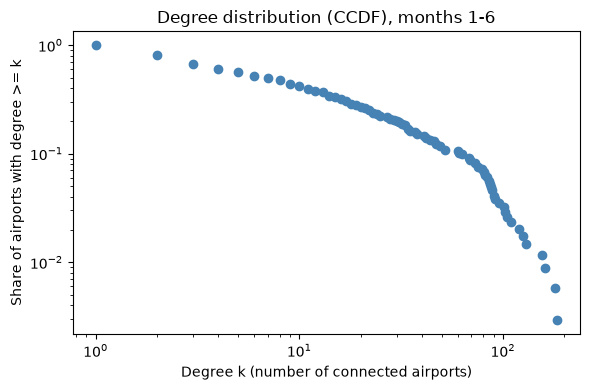

Airports with degree >= 100: 11
Airports with degree <= 3: 136


In [3]:
degree_values = np.sort(np.array(degrees))
unique_degrees = np.unique(degree_values)

share_at_least = []
for k in unique_degrees:
    share_at_least.append(np.mean(degree_values >= k))

fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(unique_degrees, share_at_least, marker="o", linestyle="none", color="steelblue")
ax.set_xlabel("Degree k (number of connected airports)")
ax.set_ylabel("Share of airports with degree >= k")
ax.set_title("Degree distribution (CCDF), months 1-6")
save_fig(fig, "degree_distribution")

print("Airports with degree >= 100:", int(np.sum(degree_values >= 100)))
print("Airports with degree <= 3:", int(np.sum(degree_values <= 3)))

**Takeaway:** 11 airports connect to 100 or more others, while 136 (40%) have 3 connections or fewer. This is the hub-and-spoke structure.

## Louvain communities
Louvain groups airports so that most flights stay inside the groups (measured by modularity). First we check the resolution, then we run 20 seeds because the result depends on the seed, and keep the run with the highest modularity.

In [4]:
# try a few resolutions
resolution_rows = []
for resolution in [0.5, 0.75, 1.0, 1.25, 1.5, 2.0]:
    communities = louvain_communities(graph, weight="flights", resolution=resolution, seed=RANDOM_SEED)
    score = modularity(graph, communities, weight="flights")
    resolution_rows.append({"resolution": resolution, "communities": len(communities), "modularity": score})

display(pd.DataFrame(resolution_rows))

,resolution,communities,modularity
0,0.500,2,0.022
1,0.750,2,0.235
2,1.000,5,0.253
3,1.250,7,0.234
4,1.500,10,0.202
5,2.000,17,0.153


In [5]:
# run Louvain with 20 seeds
with track("louvain_20_seeds", airports=graph.number_of_nodes()):
    all_runs = []
    for seed in range(20):
        communities = louvain_communities(graph, weight="flights", seed=seed)
        all_runs.append(communities)

modularities = []
for communities in all_runs:
    modularities.append(modularity(graph, communities, weight="flights"))

# keep the best run, community 0 = largest
best_run = all_runs[int(np.argmax(modularities))]
best_run_sorted = sorted(best_run, key=len, reverse=True)
louvain = community_labels(best_run_sorted, airport_list)

# compare every run with the best one
seed_rows = []
for seed, communities in enumerate(all_runs):
    run_labels = community_labels(communities, airport_list)
    seed_rows.append({
        "seed": seed,
        "communities": len(communities),
        "modularity": modularities[seed],
        "ARI_vs_best": adjusted_rand_score(louvain, run_labels),
    })
seed_table = pd.DataFrame(seed_rows)

seed_summary = seed_table.drop(columns="seed").describe()
display(seed_summary.loc[["mean", "min", "max"]])

print("Number of communities:", len(best_run))
print("Modularity:", round(max(modularities), 3))

[louvain_20_seeds] runtime: 4.26 s | peak memory (Python/pandas): 1.6 MB | peak memory (pyarrow pool): 0.3 MB


,communities,modularity,ARI_vs_best
mean,4.350,0.254,0.847
min,4.000,0.250,0.645
max,6.000,0.256,1.000


Number of communities: 4
Modularity: 0.256


**Takeaway:** Modularity is highest around resolution 1, so we keep the default. Over 20 seeds Louvain finds 4 to 6 communities; the best run has 4 communities and modularity 0.256, a moderate structure.

## What the communities look like
For each community: number of airports, flights, the share of its flights that stay inside, and its five busiest airports. We name each community after its busiest airport.

In [6]:
degree_list = []
flights_list = []
for airport in airport_list:
    degree_list.append(graph.degree(airport))
    flights_list.append(flights_per_airport[airport])

airports = pd.DataFrame({
    "airport": airport_list,
    "louvain": louvain,
    "flights": flights_list,
    "degree": degree_list,
})

# airport -> community
community_of = {}
for airport, community in zip(airport_list, louvain):
    community_of[airport] = int(community)

# count flights inside each community (both ends, like flights_per_airport)
n_communities = louvain.max() + 1
flights_inside = pd.Series(0.0, index=range(n_communities))
for airport_a, airport_b, flights in graph.edges(data="flights"):
    if community_of[airport_a] == community_of[airport_b]:
        flights_inside[community_of[airport_a]] += 2 * flights

summary = airports.groupby("louvain").agg(
    airports=("airport", "size"),
    flights=("flights", "sum"),
)
summary["share_inside"] = flights_inside / summary["flights"]

# five busiest airports per community
airports_by_flights = airports.sort_values("flights", ascending=False)
top_airports = {}
for community in summary.index:
    in_community = airports_by_flights[airports_by_flights["louvain"] == community]
    top_airports[community] = ", ".join(in_community["airport"].head(5))
summary["top_airports"] = pd.Series(top_airports)

# name = busiest airport
community_names = {}
for community in summary.index:
    busiest_airport = top_airports[community].split(", ")[0]
    community_names[community] = busiest_airport + " community"
summary.insert(0, "name", pd.Series(community_names))

display(summary)
summary.to_csv(TABLES_DIR / "03_louvain_communities.csv")

,name,airports,flights,share_inside,top_airports
louvain,,,,,
0,DEN community,120,2142268,0.657,"DEN, PHX, LAX, LAS, SEA"
1,ATL community,100,3194494,0.695,"ATL, CLT, MCO, LGA, DCA"
2,ORD community,65,553837,0.264,"ORD, MSP, GRR, MSN, SFB"
3,DFW community,58,1032027,0.327,"DFW, IAH, AUS, DAL, STL"


**Takeaway:** The communities are regions around big hubs: DEN (West), ATL (East), ORD (Central-North) and DFW (South-Central). East and West keep most of their flights inside (66–70%), while ORD and DFW are more open (26–33%), which makes sense for connecting hubs.

## Map of the communities
Each airport is drawn at its location, coloured by its Louvain community and sized by its number of flights; the 300 busiest routes are drawn in grey. Alaska and Hawaii are shown as small insets; Guam and Saipan are left out of the map.

The coordinates come from the `airportsdata` package and are only used to draw this map, not in any analysis.

Airports with coordinates: 343 of 343
Missing: []


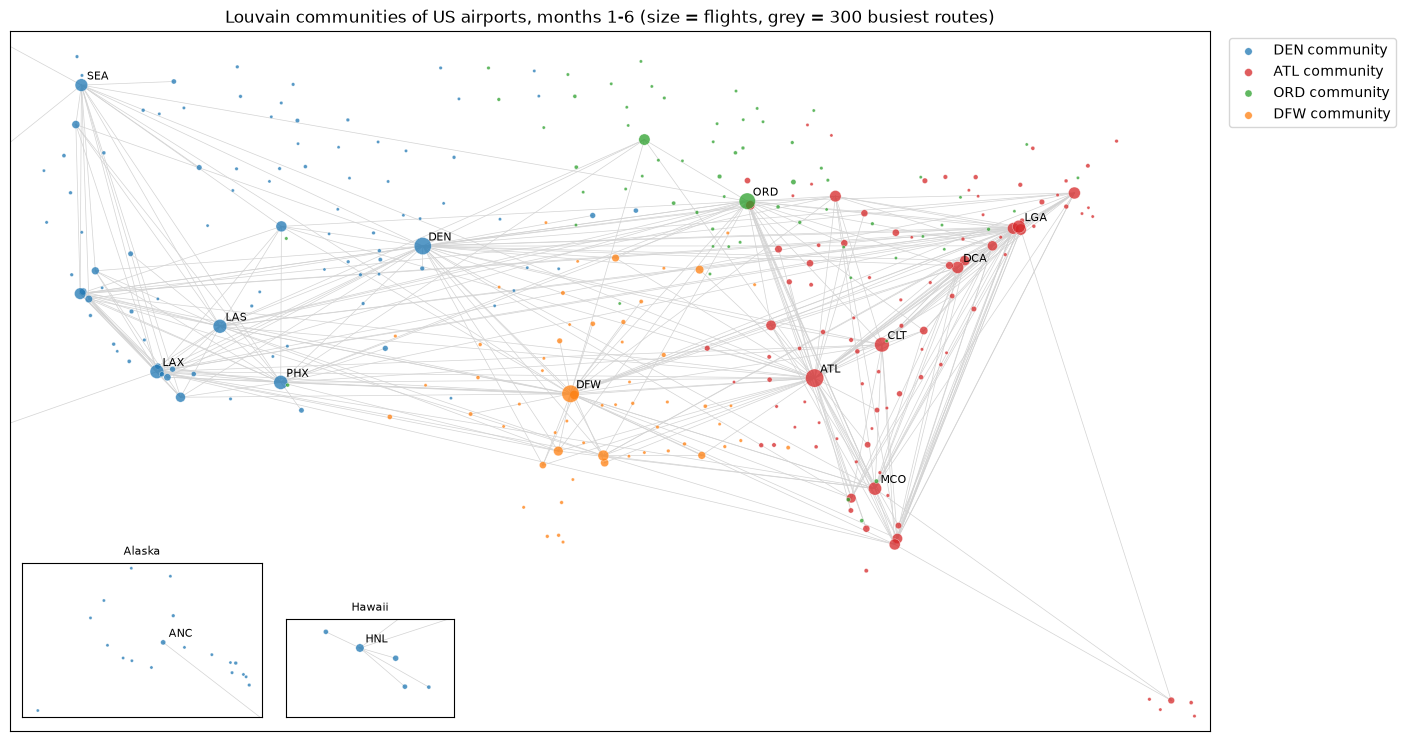

In [7]:
import airportsdata

# coordinates only for drawing the map (airportsdata package, not used in any analysis)
airport_info = airportsdata.load("IATA")

missing = []
for airport in airport_list:
    if airport not in airport_info:
        missing.append(airport)
print("Airports with coordinates:", len(airport_list) - len(missing), "of", len(airport_list))
print("Missing:", missing)

# fill missing airports by hand here if needed: {"XXX": (lat, lon)}, with the source in a comment
manual_coordinates = {}

latitude = {}
longitude = {}
for airport in airport_list:
    if airport in manual_coordinates:
        latitude[airport], longitude[airport] = manual_coordinates[airport]
    else:
        latitude[airport] = airport_info[airport]["lat"]
        longitude[airport] = airport_info[airport]["lon"]

# a copy, so the coordinates do not end up in the airport table used by RQ3
map_airports = airports.copy()
map_airports["lat"] = map_airports["airport"].map(latitude)
map_airports["lon"] = map_airports["airport"].map(longitude)
map_airports["community_name"] = map_airports["louvain"].map(community_names).str.replace(" community", "")

community_colours = {"DEN": "tab:blue", "ATL": "tab:red", "ORD": "tab:green", "DFW": "tab:orange"}

# the 300 busiest routes, drawn in grey under the airports
busiest_routes = sorted(graph.edges(data="flights"), key=lambda edge: edge[2], reverse=True)[:300]


def draw_map(ax, lon_range, lat_range, label_airports):
    for airport_a, airport_b, flights in busiest_routes:
        ax.plot([longitude[airport_a], longitude[airport_b]], [latitude[airport_a], latitude[airport_b]],
                color="lightgrey", linewidth=0.5, zorder=1)
    for name, colour in community_colours.items():
        in_community = map_airports[map_airports["community_name"] == name]
        ax.scatter(in_community["lon"], in_community["lat"], s=5 + in_community["flights"] / 2000,
                   color=colour, alpha=0.75, edgecolor="white", linewidth=0.3, label=name + " community", zorder=2)
    for airport in label_airports:
        ax.annotate(airport, (longitude[airport], latitude[airport]), xytext=(4, 4),
                    textcoords="offset points", fontsize=8, zorder=3)
    ax.set_xlim(lon_range)
    ax.set_ylim(lat_range)
    ax.set_xticks([])
    ax.set_yticks([])


busiest_airports = list(airports.nlargest(12, "flights")["airport"])

fig = plt.figure(figsize=(12, 7))
ax_main = fig.add_axes([0.0, 0.0, 1.0, 1.0])
draw_map(ax_main, (-126, -64), (17, 50), busiest_airports)
ax_main.set_title("Louvain communities of US airports, months 1-6 (size = flights, grey = 300 busiest routes)")
ax_main.legend(loc="upper left", bbox_to_anchor=(1.01, 1), markerscale=0.6)

# Alaska and Hawaii as small insets (Guam and Saipan are not shown)
ax_alaska = fig.add_axes([0.01, 0.02, 0.2, 0.22])
draw_map(ax_alaska, (-180, -129), (51, 72), ["ANC"])
ax_alaska.set_title("Alaska", fontsize=8)
ax_hawaii = fig.add_axes([0.23, 0.02, 0.14, 0.14])
draw_map(ax_hawaii, (-161, -154), (18.5, 22.5), ["HNL"])
ax_hawaii.set_title("Hawaii", fontsize=8)

fig.savefig(FIGURES_DIR / "03_community_map.png", dpi=150, bbox_inches="tight")
plt.show()


**Takeaway:** On the map the four communities are clear regions: the West around DEN (including Alaska and Hawaii), the South-Central around DFW, the East around ATL and a smaller Centre-North group around ORD and MSP. The few green points in Florida are the Allegiant leisure airports that end up in the ORD community, and Puerto Rico and the Virgin Islands belong to the East.

## Airlines inside each community
Top 3 airlines on the flights that stay inside each community. This shows if a community follows an airline network and not only geography.

In [8]:
flights = load_flights(CLEAN_PARQUET, columns=["month", "origin", "dest", "op_unique_carrier"])
flights = flights[flights["month"] <= 6]

flights["c_origin"] = flights["origin"].astype(str).map(community_of)
flights["c_dest"] = flights["dest"].astype(str).map(community_of)

# only flights that stay inside one community
inside_flights = flights[flights["c_origin"] == flights["c_dest"]]

counts = inside_flights.groupby(["c_origin", "op_unique_carrier"], observed=True).size()
counts = counts.rename("flights").reset_index()
community_totals = counts.groupby("c_origin")["flights"].transform("sum")
counts["share"] = counts["flights"] / community_totals

# top 3 per community
top3_parts = []
for community in sorted(counts["c_origin"].unique()):
    in_community = counts[counts["c_origin"] == community]
    in_community = in_community.sort_values("flights", ascending=False)
    top3_parts.append(in_community.head(3))

top3 = pd.concat(top3_parts)
top3 = top3.rename(columns={"c_origin": "louvain", "op_unique_carrier": "airline"})

display(top3.set_index(["louvain", "airline"]))
top3.to_csv(TABLES_DIR / "03_community_airlines.csv", index=False)

flights  share
louvain airline                
0       WN        212096  0.301
        OO        177078  0.252
        AS         77766  0.111
1       DL        208020  0.187
        WN        169107  0.152
        AA        156683  0.141
2       OO         36502  0.499
        G4         15683  0.214
        MQ          6378  0.087
3       WN         56746  0.336
        MQ         49314  0.292
        AA         26246  0.156

**Takeaway:** In the ORD community, SkyWest (50%) and Allegiant (21%) carry most of the internal flights, which explains why Allegiant's leisure airports (SFB, PIE, PGD, AZA) end up with ORD and MSP. So the communities follow airline networks as well as geography.

## Spectral clustering (comparison)
We compare Louvain with spectral clustering, using raw, log and binary weights and k = 4, 5, 6.

In [9]:
# flights between each pair of airports
adjacency = nx.to_numpy_array(graph, nodelist=airport_list, weight="flights")

weight_versions = {
    "raw flights": adjacency,
    "log(1 + flights)": np.log1p(adjacency),
    "binary": (adjacency > 0).astype(float),
}


def run_spectral(weights, k):
    model = SpectralClustering(k, affinity="precomputed", assign_labels="cluster_qr", random_state=RANDOM_SEED)
    return model.fit_predict(weights)


def groups_from_labels(labels):
    # list of sets of airports, one set per group
    airport_array = np.array(airport_list)
    groups = []
    for group_number in np.unique(labels):
        groups.append(set(airport_array[labels == group_number]))
    return groups


spectral_rows = []
for weight_name, weights in weight_versions.items():
    for k in [4, 5, 6]:
        spectral_labels = run_spectral(weights, k)
        groups = groups_from_labels(spectral_labels)

        group_sizes = []
        for size in sorted(np.bincount(spectral_labels), reverse=True):
            group_sizes.append(int(size))

        spectral_rows.append({
            "weights": weight_name,
            "k": k,
            "group_sizes": group_sizes,
            "modularity": modularity(graph, groups, weight="flights"),
            "ARI_vs_louvain": adjusted_rand_score(louvain, spectral_labels),
        })

spectral = pd.DataFrame(spectral_rows)
display(spectral)
spectral.to_csv(TABLES_DIR / "03_spectral_vs_louvain.csv", index=False)

# which airports are in the small groups?
labels_k4 = run_spectral(weight_versions["log(1 + flights)"], 4)
for group in groups_from_labels(labels_k4):
    if len(group) < 50:
        print("Small group:", ", ".join(sorted(group)))

,weights,k,group_sizes,modularity,ARI_vs_louvain
0,raw flights,4,"[257, 65, 19, 2]",0.181,0.126
1,raw flights,5,"[259, 58, 20, 4, 2]",0.176,0.103
2,raw flights,6,"[168, 148, 13, 7, 5, 2]",0.237,0.342
3,log(1 + flights),4,"[317, 15, 6, 5]",0.015,-0.019
4,log(1 + flights),5,"[181, 141, 13, 6, 2]",0.228,0.375
5,log(1 + flights),6,"[177, 93, 45, 19, 6, 3]",0.183,0.308
6,binary,4,"[318, 13, 7, 5]",0.011,-0.019
7,binary,5,"[184, 137, 12, 7, 3]",0.217,0.370
8,binary,6,"[185, 137, 11, 4, 4, 2]",0.218,0.370


Small group: GUM, HNL, ITO, PPG, SPN
Small group: GST, JNU, KTN, PSG, SIT, WRG
Small group: ADK, ADQ, AKN, ANC, BET, BRW, CDV, DLG, FAI, KOA, OGG, OME, OTZ, SCC, YAK


Spectral clustering spends its first groups on Alaska, Hawaii and the islands, which hardly connect to the rest. For a fairer comparison we run it again on the mainland only (all 48 contiguous states + DC) and compare with the Louvain communities of the same airports.

In [10]:
# state of every airport (from departing and arriving flights)
states = load_flights(CLEAN_PARQUET, columns=["origin", "dest", "origin_state_nm", "dest_state_nm"])
state_of = {}
for airport, state in zip(states["origin"].astype(str), states["origin_state_nm"].astype(str)):
    state_of[airport] = state
for airport, state in zip(states["dest"].astype(str), states["dest_state_nm"].astype(str)):
    state_of[airport] = state

not_mainland = ["Alaska", "Hawaii", "Puerto Rico", "U.S. Virgin Islands",
                "U.S. Pacific Trust Territories and Possessions"]
mainland_airports = []
for airport in airport_list:
    if state_of[airport] not in not_mainland:
        mainland_airports.append(airport)
print("Mainland airports:", len(mainland_airports), "of", len(airport_list))

mainland_graph = graph.subgraph(mainland_airports).copy()
print("Mainland graph connected:", nx.is_connected(mainland_graph))

# Louvain labels of the same airports, for the comparison
louvain_of = dict(zip(airport_list, louvain))
louvain_mainland = []
for airport in mainland_airports:
    louvain_mainland.append(louvain_of[airport])

mainland_adjacency = nx.to_numpy_array(mainland_graph, nodelist=mainland_airports, weight="flights")
mainland_weights = {
    "raw flights": mainland_adjacency,
    "log(1 + flights)": np.log1p(mainland_adjacency),
    "binary": (mainland_adjacency > 0).astype(float),
}

mainland_rows = []
for weight_name, weights in mainland_weights.items():
    for k in [3, 4, 5]:
        spectral_labels = run_spectral(weights, k)

        groups = []
        airport_array = np.array(mainland_airports)
        for group_number in np.unique(spectral_labels):
            groups.append(set(airport_array[spectral_labels == group_number]))

        group_sizes = []
        for size in sorted(np.bincount(spectral_labels), reverse=True):
            group_sizes.append(int(size))

        mainland_rows.append({
            "weights": weight_name,
            "k": k,
            "group_sizes": group_sizes,
            "modularity": modularity(mainland_graph, groups, weight="flights"),
            "ARI_vs_louvain": adjusted_rand_score(louvain_mainland, spectral_labels),
        })

mainland_spectral = pd.DataFrame(mainland_rows)
display(mainland_spectral)
mainland_spectral.to_csv(TABLES_DIR / "03_spectral_mainland.csv", index=False)

louvain_mainland_groups = []
for community in sorted(set(louvain_mainland)):
    group = set()
    for airport, label in zip(mainland_airports, louvain_mainland):
        if label == community:
            group.add(airport)
    louvain_mainland_groups.append(group)
print("Louvain on the same airports, modularity:",
      round(modularity(mainland_graph, louvain_mainland_groups, weight="flights"), 3))


Mainland airports: 311 of 343
Mainland graph connected: True


,weights,k,group_sizes,modularity,ARI_vs_louvain
0,raw flights,3,"[158, 149, 4]",0.223,0.392
1,raw flights,4,"[158, 110, 41, 2]",0.190,0.436
2,raw flights,5,"[128, 116, 58, 7, 2]",0.195,0.482
3,log(1 + flights),3,"[168, 81, 62]",0.026,0.113
4,log(1 + flights),4,"[149, 114, 33, 15]",0.097,0.226
5,log(1 + flights),5,"[139, 89, 66, 15, 2]",0.067,0.139
6,binary,3,"[179, 73, 59]",0.131,0.384
7,binary,4,"[177, 66, 59, 9]",0.152,0.322
8,binary,5,"[155, 107, 26, 16, 7]",0.063,0.175


Louvain on the same airports, modularity: 0.24


**Takeaway:** Spectral clustering first separates Hawaii, Alaska and the Pacific islands. With k = 4 the whole mainland stays in one group (ARI about 0 with Louvain); only from k = 5 does it split the mainland (ARI up to 0.375). On the mainland only (311 airports) it agrees more with Louvain: with raw flight weights the ARI is 0.39–0.48 for k = 3–5, but the modularity (0.19–0.22) stays below Louvain's on the same airports (0.24), and the log and binary versions agree much less (ARI 0.11–0.38). So even without the islands, spectral depends a lot on the weights and k, and we keep Louvain as the main method.

## Bridge airports (betweenness)
Betweenness counts how many shortest paths go through an airport. With distance = 1 / flights busy hubs are favoured, so we also compute it with hop count and compare the two top 15.

[betweenness] runtime: 5.97 s | peak memory (Python/pandas): 0.3 MB | peak memory (pyarrow pool): 216.1 MB


,rank,airport_weighted,betweenness_weighted,airport_hops,betweenness_hops
0,1,DEN,0.351,DFW,0.184
1,2,ATL,0.331,DEN,0.178
2,3,DFW,0.223,ORD,0.106
3,4,ORD,0.197,ATL,0.090
4,5,SEA,0.143,MSP,0.076
5,6,LAX,0.090,ANC,0.066
6,7,MSP,0.075,SEA,0.048
7,8,SLC,0.065,DTW,0.047
8,9,ANC,0.058,LAS,0.045
9,10,PHX,0.047,SLC,0.042


Spearman correlation between the two versions: 0.569
Airports in both top 15: 13


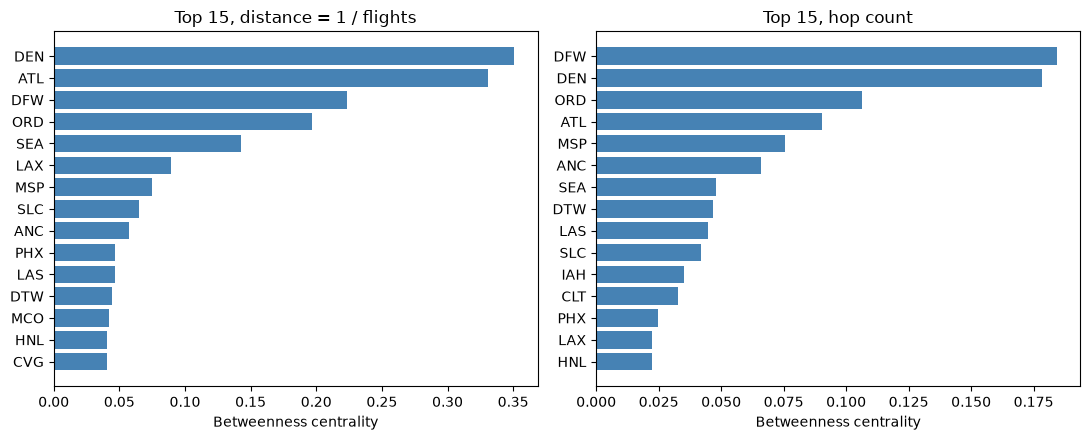

In [11]:
with track("betweenness", airports=graph.number_of_nodes()):
    betweenness_weighted = nx.betweenness_centrality(graph, weight="distance")
    betweenness_hops = nx.betweenness_centrality(graph)

airports["betweenness"] = airports["airport"].map(betweenness_weighted)
airports["betweenness_hops"] = airports["airport"].map(betweenness_hops)

top_weighted = airports.nlargest(15, "betweenness")
top_weighted = top_weighted[["airport", "betweenness"]].reset_index(drop=True)
top_hops = airports.nlargest(15, "betweenness_hops")
top_hops = top_hops[["airport", "betweenness_hops"]].reset_index(drop=True)

top = pd.DataFrame({
    "rank": range(1, 16),
    "airport_weighted": top_weighted["airport"],
    "betweenness_weighted": top_weighted["betweenness"],
    "airport_hops": top_hops["airport"],
    "betweenness_hops": top_hops["betweenness_hops"],
})
display(top)
top.to_csv(TABLES_DIR / "03_betweenness_top15.csv", index=False)

rank_correlation = spearmanr(airports["betweenness"], airports["betweenness_hops"]).statistic
in_both = set(top_weighted["airport"]) & set(top_hops["airport"])
print("Spearman correlation between the two versions:", round(rank_correlation, 3))
print("Airports in both top 15:", len(in_both))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].barh(top_weighted["airport"][::-1], top_weighted["betweenness"][::-1], color="steelblue")
axes[0].set_xlabel("Betweenness centrality")
axes[0].set_title("Top 15, distance = 1 / flights")
axes[1].barh(top_hops["airport"][::-1], top_hops["betweenness_hops"][::-1], color="steelblue")
axes[1].set_xlabel("Betweenness centrality")
axes[1].set_title("Top 15, hop count")
save_fig(fig, "top_betweenness")

**Takeaway:** DEN, ATL, DFW and ORD are the main bridges in both versions, and 13 of the 15 airports are the same. ATL drops from 2nd to 4th with hop count, so part of its score comes from traffic. ANC and HNL connect Alaska and Hawaii.

## Scalability: approximate betweenness
Exact betweenness gets slow on big networks. networkx can estimate it from k sampled airports, so we check the runtime and how many of the exact top 15 it finds. (The pyarrow memory in the printout is the peak since the kernel started, not of this step.)

In [12]:
exact_top15 = set(top_weighted["airport"])

with track("betweenness_exact", airports=graph.number_of_nodes()) as stats:
    nx.betweenness_centrality(graph, weight="distance")
scalability_rows = [{"k_samples": "exact (343)", "runtime_s": stats["runtime_s"], "top15_recovered": 15}]

for k in [25, 50, 100, 200]:
    with track("betweenness_approx", k=k) as stats:
        approx = nx.betweenness_centrality(graph, k=k, weight="distance", seed=RANDOM_SEED)
    approx_top15 = set(pd.Series(approx).nlargest(15).index)
    recovered = len(approx_top15 & exact_top15)
    scalability_rows.append({"k_samples": str(k), "runtime_s": stats["runtime_s"], "top15_recovered": recovered})

scalability = pd.DataFrame(scalability_rows)
display(scalability)
scalability.to_csv(TABLES_DIR / "03_betweenness_scalability.csv", index=False)

[betweenness_exact] runtime: 4.51 s | peak memory (Python/pandas): 0.2 MB | peak memory (pyarrow pool): 216.1 MB


[betweenness_approx] runtime: 0.36 s | peak memory (Python/pandas): 0.2 MB | peak memory (pyarrow pool): 216.1 MB


[betweenness_approx] runtime: 0.69 s | peak memory (Python/pandas): 0.2 MB | peak memory (pyarrow pool): 216.1 MB


[betweenness_approx] runtime: 1.37 s | peak memory (Python/pandas): 0.2 MB | peak memory (pyarrow pool): 216.1 MB


[betweenness_approx] runtime: 2.66 s | peak memory (Python/pandas): 0.2 MB | peak memory (pyarrow pool): 216.1 MB


,k_samples,runtime_s,top15_recovered
0,exact (343),4.514,15
1,25,0.357,11
2,50,0.689,14
3,100,1.366,13
4,200,2.658,14


**Takeaway:** With 50 sampled airports the estimate is several times faster (about 6–7x; exact runtimes vary between runs) and still finds 14 of the top 15. The result is random, so more samples don't always help (100 samples: 13). For a network this small the exact version is fine.

## Delays by community
Do communities differ in delays? We use completed flights from months 1–6 and give each flight the community of its origin airport. A flight is late if it arrives 15+ minutes late. With millions of flights the p-value is always about 0, so we look at the effect size (epsilon-squared: 0.01 small, 0.06 medium, 0.14 large).

In [13]:
delay_flights = load_flights(CLEAN_PARQUET, columns=["month", "origin", "dest", "status", "arr_delay", "dep_delay"])
delay_flights = delay_flights[delay_flights["month"] <= 6]
delay_flights = delay_flights[delay_flights["status"] == "completed"]

delay_flights["origin_community"] = delay_flights["origin"].astype(str).map(community_of)
delay_flights["dest_community"] = delay_flights["dest"].astype(str).map(community_of)
delay_flights["inside"] = delay_flights["origin_community"] == delay_flights["dest_community"]


def delay_summary(arr_delay):
    return {
        "flights": len(arr_delay),
        "late_share": float((arr_delay >= 15).mean()),
        "median_arr_delay": float(arr_delay.median()),
        "p90_arr_delay": float(arr_delay.quantile(0.9)),
    }


delay_rows = []

# one row per community
for community in sorted(community_names):
    in_community = delay_flights[delay_flights["origin_community"] == community]
    row = {"group": community_names[community]}
    row.update(delay_summary(in_community["arr_delay"]))
    delay_rows.append(row)

# flights inside one community vs between communities
row = {"group": "inside one community"}
row.update(delay_summary(delay_flights[delay_flights["inside"]]["arr_delay"]))
delay_rows.append(row)

row = {"group": "between communities"}
row.update(delay_summary(delay_flights[~delay_flights["inside"]]["arr_delay"]))
delay_rows.append(row)

delays_by_community = pd.DataFrame(delay_rows)
display(delays_by_community)
delays_by_community.to_csv(TABLES_DIR / "03_delays_by_community.csv", index=False)

,group,flights,late_share,median_arr_delay,p90_arr_delay
0,DEN community,1055398,0.207,-5.000,39.000
1,ATL community,1570829,0.219,-6.000,47.000
2,ORD community,272076,0.223,-7.000,52.000
3,DFW community,505169,0.249,-4.000,56.000
4,inside one community,2021798,0.211,-6.000,44.000
5,between communities,1381674,0.233,-5.000,49.000


Late share, all flights: 0.22


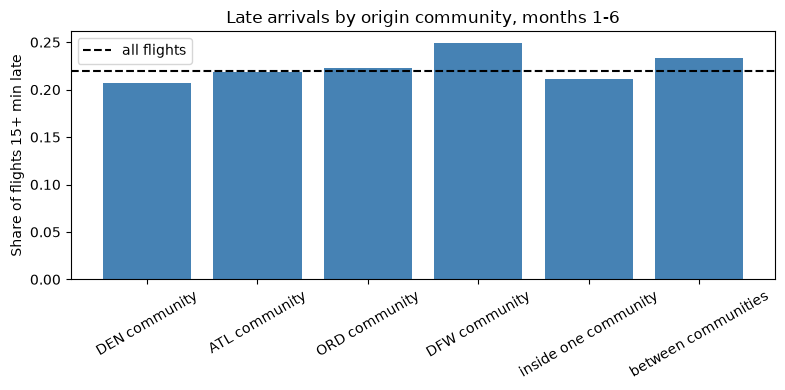

In [14]:
overall_late_share = float((delay_flights["arr_delay"] >= 15).mean())
print("Late share, all flights:", round(overall_late_share, 3))

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(delays_by_community["group"], delays_by_community["late_share"], color="steelblue")
ax.axhline(overall_late_share, color="black", linestyle="--", label="all flights")
ax.set_ylabel("Share of flights 15+ min late")
ax.set_title("Late arrivals by origin community, months 1-6")
ax.tick_params(axis="x", rotation=30)
ax.legend()
save_fig(fig, "delays_by_community")

In [15]:
# Kruskal-Wallis on the arrival delays of the 4 communities
delay_groups = []
for community in sorted(community_names):
    in_community = delay_flights[delay_flights["origin_community"] == community]
    delay_groups.append(in_community["arr_delay"])
kw_result = kruskal(*delay_groups)

# effect size
n_flights = len(delay_flights)
epsilon_squared = kw_result.statistic / (n_flights - 1)

print("Flights:", n_flights)
print("Kruskal-Wallis H:", round(kw_result.statistic, 1))
print("p-value:", kw_result.pvalue)
print("Epsilon-squared:", round(epsilon_squared, 4))

Flights: 3403472
Kruskal-Wallis H: 11165.5
p-value: 0.0
Epsilon-squared: 0.0033


Flights from the same airport are not independent (same weather, same congestion), so we also do the test per airport: each airport counts once, with the share of its departing flights that arrive 15+ minutes late.

In [16]:
late_arrivals = {}
departing_flights = {}
for airport, airport_flights in delay_flights.groupby(delay_flights["origin"].astype(str)):
    late_arrivals[airport] = float((airport_flights["arr_delay"] >= 15).mean())
    departing_flights[airport] = len(airport_flights)

airports["late_arrival_share"] = airports["airport"].map(late_arrivals)
airports["departing_flights"] = airports["airport"].map(departing_flights)

airport_groups = []
for community in sorted(community_names):
    in_community = airports[airports["louvain"] == community]
    airport_groups.append(in_community["late_arrival_share"].dropna())
airport_kw = kruskal(*airport_groups)

n_airports_tested = 0
for group in airport_groups:
    n_airports_tested += len(group)
airport_epsilon_squared = airport_kw.statistic / (n_airports_tested - 1)

print("Airports tested:", n_airports_tested)
print("Kruskal-Wallis H:", round(airport_kw.statistic, 2))
print("p-value:", airport_kw.pvalue)
print("Epsilon-squared:", round(airport_epsilon_squared, 4))

for community, group in zip(sorted(community_names), airport_groups):
    print(community_names[community], "- median airport late share:", round(group.median(), 3))

Airports tested: 343
Kruskal-Wallis H: 40.52
p-value: 8.279179630239086e-09
Epsilon-squared: 0.1185
DEN community - median airport late share: 0.167
ATL community - median airport late share: 0.195
ORD community - median airport late share: 0.2
DFW community - median airport late share: 0.201


Small airports have few departures, so their late shares are noisy. We repeat the airport-level test with only the airports with at least 500 departures, to check that the effect is not driven by small airports.

In [17]:
busy_airports = airports[airports["departing_flights"] >= 500]

busy_groups = []
for community in sorted(community_names):
    in_community = busy_airports[busy_airports["louvain"] == community]
    busy_groups.append(in_community["late_arrival_share"].dropna())
busy_kw = kruskal(*busy_groups)

n_busy_tested = 0
for group in busy_groups:
    n_busy_tested += len(group)
busy_epsilon_squared = busy_kw.statistic / (n_busy_tested - 1)

print("Airports with >= 500 departures:", n_busy_tested)
print("Kruskal-Wallis H:", round(busy_kw.statistic, 2))
print("p-value:", busy_kw.pvalue)
print("Epsilon-squared:", round(busy_epsilon_squared, 4))

for community, group in zip(sorted(community_names), busy_groups):
    print(community_names[community], "-", len(group), "airports, median late share:", round(group.median(), 3))


Airports with >= 500 departures: 233
Kruskal-Wallis H: 25.96
p-value: 9.719356854737422e-06
Epsilon-squared: 0.1119
DEN community - 70 airports, median late share: 0.181
ATL community - 86 airports, median late share: 0.197
ORD community - 31 airports, median late share: 0.201
DFW community - 46 airports, median late share: 0.202


Are bridge airports more delayed? Here we use late departures (15+ minutes), because departure delay says more about the airport itself than arrival delay.

In [18]:
late_departures = {}
for airport, airport_flights in delay_flights.groupby(delay_flights["origin"].astype(str)):
    late_departures[airport] = float((airport_flights["dep_delay"] >= 15).mean())
airports["late_departure_share"] = airports["airport"].map(late_departures)

rho_weighted = spearmanr(airports["betweenness"], airports["late_departure_share"]).statistic
rho_hops = spearmanr(airports["betweenness_hops"], airports["late_departure_share"]).statistic
print("Spearman, betweenness vs late departures:", round(rho_weighted, 3))
print("Spearman, betweenness (hops) vs late departures:", round(rho_hops, 3))

# same thing without the small airports (noisy shares)
busy = airports[airports["departing_flights"] >= 500]
rho_weighted_busy = spearmanr(busy["betweenness"], busy["late_departure_share"]).statistic
rho_hops_busy = spearmanr(busy["betweenness_hops"], busy["late_departure_share"]).statistic
print("Airports with >= 500 departures:", len(busy))
print("Spearman (>= 500), betweenness vs late departures:", round(rho_weighted_busy, 3))
print("Spearman (>= 500), betweenness (hops) vs late departures:", round(rho_hops_busy, 3))

Spearman, betweenness vs late departures: 0.196
Spearman, betweenness (hops) vs late departures: 0.303
Airports with >= 500 departures: 233
Spearman (>= 500), betweenness vs late departures: 0.234
Spearman (>= 500), betweenness (hops) vs late departures: 0.272


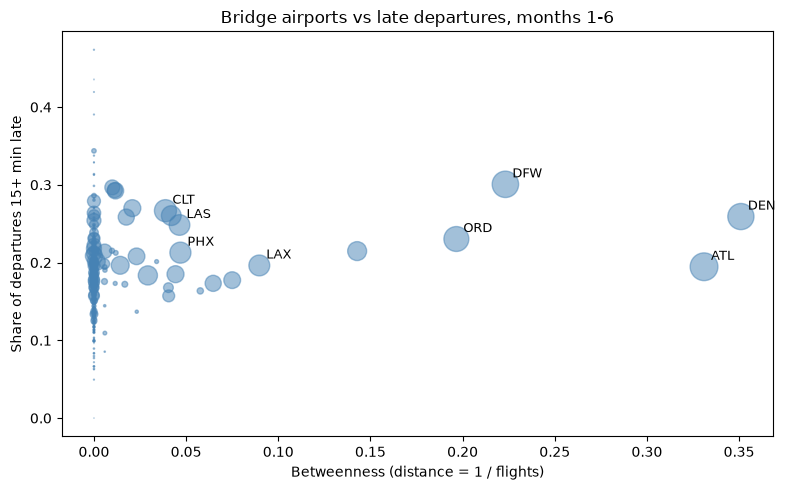

In [19]:
fig, ax = plt.subplots(figsize=(8, 5))
point_sizes = airports["flights"] / airports["flights"].max() * 400
ax.scatter(airports["betweenness"], airports["late_departure_share"], s=point_sizes, alpha=0.5, color="steelblue")

# label the 8 busiest airports
busiest = airports.nlargest(8, "flights")
for row in busiest.itertuples():
    ax.annotate(row.airport, (row.betweenness, row.late_departure_share),
                textcoords="offset points", xytext=(5, 5), fontsize=9)

ax.set_xlabel("Betweenness (distance = 1 / flights)")
ax.set_ylabel("Share of departures 15+ min late")
ax.set_title("Bridge airports vs late departures, months 1-6")
save_fig(fig, "betweenness_vs_delay")

**Takeaway:** Per flight, the differences are small: 20.7% late in the DEN community vs 24.9% in DFW (22.0% overall), and flights between communities are late a bit more often (23.3% vs 21.1%), although these flights are also longer and pass through hubs, which can explain part of the gap. The effect size is tiny (0.003), so the community explains little of a single flight's delay. Per airport the effect is medium (0.12): the typical DEN-community airport has 16.7% late flights, against about 20% in the others. It holds with only the 233 airports with 500+ departures (epsilon-squared 0.11), so it is not driven by small airports. Bridge airports have slightly more late departures (Spearman 0.20–0.30, and 0.23–0.27 for airports with 500+ departures).

## Are the communities stable over time?
RQ3 uses the months 1–6 communities for all test months, so we check if they still hold in months 7–12. We run the same 20-seed Louvain on months 7–12 (only airports in both periods) and compare with ARI. As reference, the seed-to-seed ARI in months 1–6 was 0.85.

In [20]:
all_flights = load_flights(CLEAN_PARQUET, columns=["month", "origin", "dest"])
edges_late = build_edges(all_flights, months=range(7, 13))
graph_late = build_graph(edges_late)

# airports in both periods
common_airports = sorted(set(graph) & set(graph_late))
only_early = sorted(set(graph) - set(graph_late))
only_late = sorted(set(graph_late) - set(graph))
graph_late = graph_late.subgraph(common_airports).copy()

print("Airports in both periods:", len(common_airports))
print("Only in months 1-6:", ", ".join(only_early))
print("Only in months 7-12:", ", ".join(only_late))

# same procedure as before: 20 seeds, keep the best
late_runs = []
late_modularities = []
for seed in range(20):
    communities = louvain_communities(graph_late, weight="flights", seed=seed)
    late_runs.append(communities)
    late_modularities.append(modularity(graph_late, communities, weight="flights"))

best_late = late_runs[int(np.argmax(late_modularities))]
best_late_sorted = sorted(best_late, key=len, reverse=True)
late_labels = community_labels(best_late_sorted, common_airports)

early_labels = []
for airport in common_airports:
    early_labels.append(community_of[airport])

period_ari = adjusted_rand_score(early_labels, late_labels)
print("Communities in months 7-12:", len(best_late))
print("Modularity in months 7-12:", round(max(late_modularities), 3))
print("ARI months 1-6 vs 7-12:", round(period_ari, 3))
print("Seed-to-seed ARI in months 1-6, mean:", round(seed_table["ARI_vs_best"].mean(), 3))
print("Seed-to-seed ARI in months 1-6, min:", round(seed_table["ARI_vs_best"].min(), 3))

Airports in both periods: 341
Only in months 1-6: CNY, VEL
Only in months 7-12: EAR, EAU, EWN, MGW, PQI


Communities in months 7-12: 4
Modularity in months 7-12: 0.255
ARI months 1-6 vs 7-12: 0.735
Seed-to-seed ARI in months 1-6, mean: 0.847
Seed-to-seed ARI in months 1-6, min: 0.645


In [21]:
# where do the airports of each community go in months 7-12?
early_names = []
for label in early_labels:
    early_names.append(community_names[label])

crosstab = pd.crosstab(
    pd.Series(early_names, name="months 1-6"),
    pd.Series(late_labels, name="months 7-12 community"),
)
display(crosstab)
crosstab.to_csv(TABLES_DIR / "03_community_stability.csv")

months 7-12 community,0,1,2,3
months 1-6,,,,
ATL community,100,0,0,0
DEN community,0,118,0,0
DFW community,7,0,51,0
ORD community,36,3,1,25


**Takeaway:** The ARI between the two periods is 0.74, a bit below the seed-to-seed reference (0.85). The ATL and DEN communities are exactly the same and DFW keeps 51 of its 58 airports, but the ORD community mostly falls apart (36 of its 65 airports join the East). So using the months 1–6 communities in RQ3 is fine, but the ORD community is the least reliable one.

## Output for RQ3
One row per airport with its community, betweenness, degree, flights and delay shares (months 1–6).

In [22]:
airports.to_csv(TABLES_DIR / "03_airports.csv", index=False)
print("Number of airports saved:", len(airports))

Number of airports saved: 343


## Limitations
- Louvain depends on the seed: 4 to 6 communities over 20 seeds (mean ARI 0.85). We keep the run with the highest modularity.
- We only use months 1–6 on purpose, so RQ3 doesn't see its test months. Because of this, EAR, EAU, EWN, MGW and PQI (flights only after June) have no community.
- The communities change a bit over time (ARI 0.74 with months 7–12), mostly the ORD community.
- Spectral clustering mainly separates Hawaii and Alaska and depends a lot on k and the weights, also on the mainland only, so it is only a comparison.
- Flights are not independent (same airport, same day), so the flight-level test is too optimistic. The airport-level test helps, but we still read effect sizes rather than p-values.